## Libaries

In [63]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os
from scipy import stats

## Paths

In [3]:
### INPUT ###
conc_data_path = r"C:\Users\joels\Desktop\ResearchProject\Phytoplankton_Modeling\Data\AVP2016_concentrations_data.xlsx"
conc_data = pd.read_excel(conc_data_path)
conc_data = conc_data[:][0:-3] # Remove NaN rows

model_output_path = r"C:\Users\joels\Desktop\ResearchProject\Phytoplankton_Modeling\Results\Dataframes\Carbon_model_calcifcation_attempt2.xlsx"
model_output = pd.read_excel(model_output_path)

In [59]:
### OUTPUT ###
output_dir = r"C:\Users\joels\Desktop\ResearchProject\Phytoplankton_Modeling\Results"

In [6]:
model_output['date'] = pd.date_range(start="2016-05-18", periods=len(model_output), freq="h")

In [7]:
# data = {'date': model_output['date'],
#         'SA': model_output['SA'],
#         'IAP': model_output['IAP'],
#         'K_sp': model_output['K_sp']
#        }

In [12]:
data = {'date': conc_data['date'],
        'Ca': conc_data['Ca']
       }

df = pd.DataFrame(data)

In [14]:
for i in range(1,len(df)):
    dCa = df['Ca'][i] - df['Ca'][i-1] # Calcium difference in umol/L
    dCa_molL = dCa * (10**-6)  # # Calcium difference in mol/L
    
    dt = df['date'][i] - df['date'][i-1]  # time difference in days
    dt_h = dt.total_seconds() / (60*60)  # time difference in hours

    Ca_molL_h = dCa_molL / dt_h
    df.loc[i, 'Ca_molL_h'] = Ca_molL_h

In [17]:
merged = pd.merge_asof(
    model_output,
    df,
    left_on="date",
    right_on="date",
    direction="backward"
)

In [19]:
merged['SA_IAP_K_sp'] = merged['SA_phyto'] * (merged['IAP'] - merged['K_sp'])

In [21]:
for i in range(1, len(df)):
    t_start = df['date'][i-1]
    t_end   = df['date'][i]
    mask = (merged['date'] >= t_start) & (merged['date'] < t_end)
    df.loc[i, 'SA_IAP_K_sp_mean'] = merged.loc[mask, 'SA_IAP_K_sp'].mean()

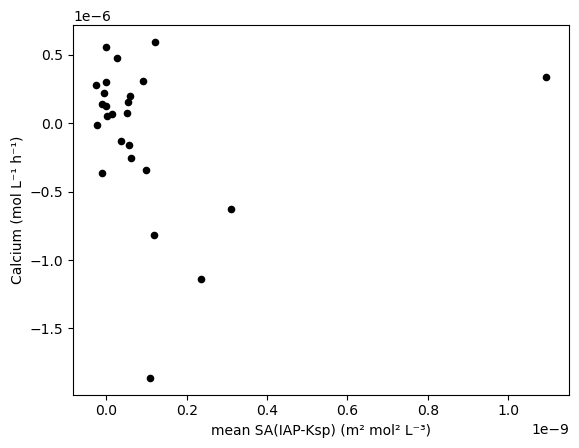

In [65]:
plot = df.plot(kind="scatter", x= 'SA_IAP_K_sp_mean', y='Ca_molL_h', s=20, color='black')
plot.set_ylabel('Calcium (mol L⁻¹ h⁻¹)')
plot.set_xlabel('mean SA(IAP-Ksp) (m² mol² L⁻³)')

############ Saving ############
out = os.path.join(output_dir, "Plots\\kf_calculation")
plt.savefig(out)
################################
plt.show()

In [37]:
slope, intercept, r_value, p_value, std_err = stats.linregress(df['SA_IAP_K_sp_mean'].values, df['Ca_molL_h'].values)

print(f"Formula: Ca_molL_h = {intercept:.4f} + {slope:.4f} * SAS * (IAP - Ksp)")
lin_cor = df['SA_IAP_K_sp_mean'].corr(df['Ca_molL_h'])
print(f'Linear correlation: {lin_cor}')
nonlin_cor = df['SA_IAP_K_sp_mean'].corr(df['Ca_molL_h'], method='spearman')
print(f'Nonlinear correlation: {nonlin_cor}')
nonpara_cor = df['SA_IAP_K_sp_mean'].corr(df['Ca_molL_h'], method='kendall')   # Nonparametric measure using Kendall's Tau correlation coefficient
print(f'Nonparametric correlation: {nonpara_cor}')
print(f'r-value: {r_value}')

Formula: Ca_molL_h = nan + nan * SAS * (IAP - Ksp)
Linear correlation: -0.05002537234286814
Nonlinear correlation: -0.25466436324132874
Nonparametric correlation: -0.20367307180472422
r-value: nan


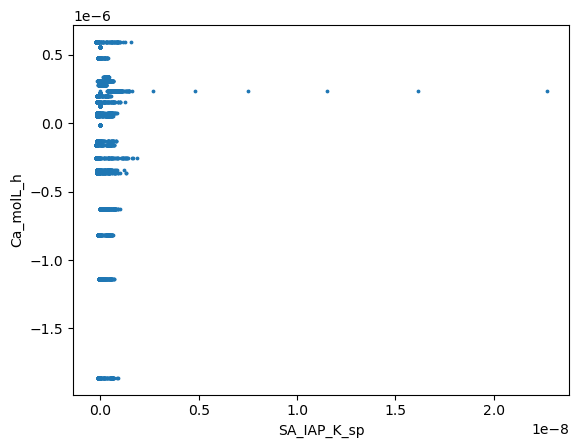

In [25]:
# SA (IAP-Ksp)



plot = merged.plot(kind="scatter", x= 'SA_IAP_K_sp', y='Ca_molL_h', s=3)

In [27]:
slope, intercept, r_value, p_value, std_err = stats.linregress(df['SA_IAP_K_sp'].values, df['Ca_molL_h'].values)

print(f"Formula: Ca_molL_h = {intercept:.4f} + {slope:.4f} * SAS * (IAP - Ksp)")

KeyError: 'SA_IAP_K_sp'